# TP3 — Partie 1 : des données de films à une API de prédiction

**Nom :** Omar El Hamdaoui  
**Contribution :** étude du jeu de films, ajout du traitement PySpark, régression et déploiement local.  
**État du notebook :** les cellules ont été exécutées de bout en bout sans erreur enregistrée.  
**Problèmes rencontrés :** aucun échec dans l’exécution enregistrée ; les dépendances et données sont décrites dans le README.  
**Modifications apportées :** acquisition reproductible, contrôle qualité, visualisations, transformations, comparaison de modèles, évaluation et API locale.
**Jeu : Trending Movies Dataset (Up to 2026) — version 1.**

**Question :** peut-on estimer la note moyenne d'un film à partir de sa date de sortie, de sa langue et de son synopsis ?
Nous traitons une **régression supervisée**, sur les films ayant au moins 30 votes et déjà sortis à la date du snapshot.
Le résultat est une estimation de note observée dans ce catalogue, pas une prévision garantie du succès commercial.

Parcours : acquisition → EDA → prétraitement → transformation → comparaison ML → évaluation finale → API locale.
Les cellules sont exécutables dans l'ordre avec le noyau **Python (TP3)**. Installation et commandes : `README.md`.

## Data


## 1. Environnement et acquisition reproductible
Le téléchargement demandé utilise `kagglehub`. Nous figeons la version 1 pour pouvoir reproduire les résultats.
Une copie déjà présente est réutilisée ; taille et empreinte SHA-256 sont enregistrées.
Lors de la préparation initiale, le même fichier a été récupéré par l'API publique Kaggle pendant l'installation des dépendances.

In [1]:
from pathlib import Path
import hashlib, json, os, shutil, sys, time
NOTEBOOK_NAME='trending-movies-analysis-up-to-2026_small_data.ipynb'
candidates=[Path.cwd(),Path.cwd()/'Small',Path.cwd()/'Big',
            *Path.cwd().glob('TP3_ID*/Small'),*Path.cwd().glob('TP3_ID*/Big'),
            *Path.cwd().parents]
ROOT=next(p.resolve() for p in candidates if (p/NOTEBOOK_NAME).exists())
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 20)
DATASETS = {'films': {'ref':'sahilk22/trending-movies-analysis-up-to-2026', 'version':1,
                     'file':'Treanding_movies.csv', 'folder':'movies', 'bytes':3471451}}

def save_json(value, path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,ensure_ascii=False,indent=2,default=str),encoding='utf-8')

def acquire(name):
    spec=DATASETS[name]
    path=ROOT/'data/raw'/spec['folder']/spec['file']
    if not path.exists():
        import kagglehub
        os.environ.setdefault('KAGGLEHUB_CACHE',str(ROOT/'data/kagglehub'))
        source=Path(kagglehub.dataset_download(f"{spec['ref']}/versions/{spec['version']}",path=spec['file']))
        path.parent.mkdir(parents=True,exist_ok=True)
        try: os.link(source,path)
        except OSError: shutil.copyfile(source,path)
    digest=hashlib.sha256(); total=0
    with open(path,'rb') as handle:
        for chunk in iter(lambda:handle.read(8*1024*1024),b''):
            total+=len(chunk); digest.update(chunk)
    if total!=spec['bytes']: raise ValueError(f"Fichier incomplet ou version inattendue : {path}")
    save_json({**spec,'sha256':digest.hexdigest(),'local_path':str(path.relative_to(ROOT)),
               'stored_bytes':path.stat().st_size,'compression':'none'},ROOT/'reports/provenance_films.json')
    return path

RAW_FEATURES=['release_date','original_language','overview']
NUMERIC=['release_year','release_month','overview_words','overview_chars']
CATEGORICAL=['original_language']
def movie_features(frame):
    frame=pd.DataFrame(frame).copy()
    dates=pd.to_datetime(frame['release_date'],errors='coerce')
    text=frame['overview'].fillna('').astype(str)
    return pd.DataFrame({'release_year':dates.dt.year.astype(float),'release_month':dates.dt.month.astype(float),
        'overview_words':np.log1p(text.str.split().str.len()),'overview_chars':np.log1p(text.str.len()),
        'original_language':frame['original_language'].fillna('unknown').astype(str),'overview':text},index=frame.index)
print('Racine :', ROOT)

Racine : /home/omar/Bureau/5A/big data/TP 3/Big-data-tp3-small


In [2]:
path = acquire('films')
raw = pd.read_csv(path)
print(f'{len(raw):,} lignes, {raw.shape[1]} colonnes ; {path.stat().st_size / 1e6:.2f} Mo')
display(raw.head(3))
display(pd.read_json(ROOT/'reports/provenance_films.json', typ='series').to_frame('Valeur'))

10,000 lignes, 11 colonnes ; 3.47 Mo


,Unnamed: 0,id,title,original_title,overview,popularity,release_date,original_language,adult,vote_count,vote_average
0,0,969681,Spider-Man: Brand New Day,Spider-Man: Brand New Day,Fighting crime full-time as Spider-Man in a wo...,1284.3495,2026-07-29,en,False,5923,8.470
1,1,687163,Project Hail Mary,Project Hail Mary,Science teacher Ryland Grace wakes up on a spa...,1080.0306,2026-03-15,en,False,8418,8.636
2,2,1003596,Avengers: Doomsday,Avengers: Doomsday,Beloved heroes from three distinct universes a...,817.9340,2026-12-16,en,False,0,0.000


,Valeur
ref,sahilk22/trending-movies-analysis-up-to-2026
version,1
file,Treanding_movies.csv
folder,movies
bytes,3471451
sha256,c0f4a142a9f6d17f975b861e098620ddd8165916c2fc5b...
local_path,data/raw/movies/Treanding_movies.csv
stored_bytes,3471451
compression,none


## EDA


## 2. EDA : structure, qualité et population
Le fichier contient les notes, les votes, la popularité, les dates, la langue et les synopsis.
Il ne contient pas de colonne de genre : aucune analyse par genre n'est inventée.
L'identifiant `id` est la clé métier. La colonne d'index exportée n'est pas une variable explicative.

In [3]:
audit = pd.DataFrame({'type':raw.dtypes.astype(str),'manquants':raw.isna().sum(),
                      'uniques':raw.nunique(dropna=True)})
audit['manquants_pct'] = 100 * audit['manquants'] / len(raw)
display(audit)
print('Lignes strictement identiques :', raw.duplicated().sum())
print('Identifiants répétés :', raw['id'].duplicated().sum())
display(raw[['vote_average','vote_count','popularity']].describe().round(3))

,type,manquants,uniques,manquants_pct
Unnamed: 0,int64,0,20,0.00
id,int64,0,9856,0.00
title,object,1,9521,0.01
original_title,object,1,9594,0.01
overview,object,60,9787,0.60
popularity,float64,0,9417,0.00
release_date,object,74,6011,0.74
original_language,object,0,55,0.00
adult,bool,0,1,0.00
vote_count,int64,0,4056,0.00


Lignes strictement identiques : 0
Identifiants répétés : 144


,vote_average,vote_count,popularity
count,10000.000,10000.000,10000.000
mean,6.401,2106.673,11.297
std,1.508,3549.843,23.115
min,0.000,0.000,2.471
25%,6.064,301.000,5.837
50%,6.620,879.500,7.499
75%,7.200,2247.750,11.342
max,10.000,41580.000,1284.350


### Analyse distribuée avec PySpark

Spark relit le CSV, contrôle le nombre de lignes et calcule les notes moyennes par langue après déduplication et filtrage des films ayant au moins 30 votes. Le résultat agrégé, seul, est converti en pandas pour le graphique. Le traitement Spark reste distinct du pipeline scikit-learn, qui utilise ensuite le même jeu pour la régression.


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 15:50:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


PySpark : 10,000 lignes ; 8,775 films avec ≥ 30 votes


,original_language,films,note_moyenne
0,en,7060,6.58
1,ja,414,7.24
2,fr,357,6.76
3,es,165,7.00
4,ko,145,7.15
5,zh,107,7.03
6,cn,96,6.84
7,de,78,6.96
8,it,76,7.13
9,ru,34,7.01


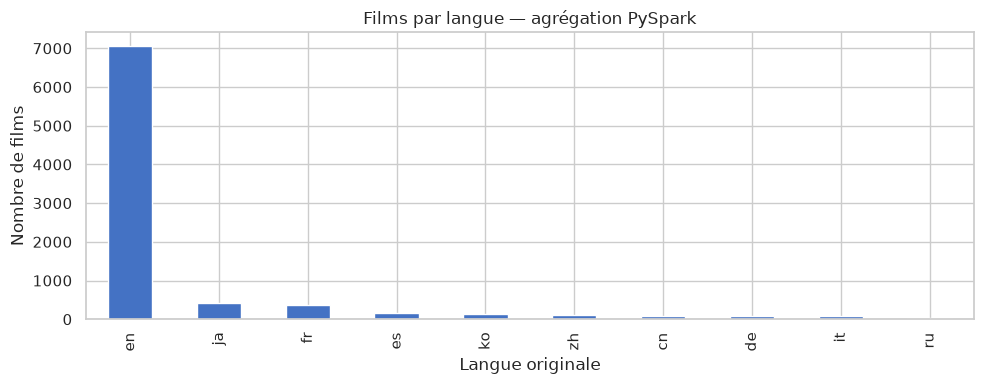

In [4]:
from pyspark.sql import SparkSession, functions as F
import os, sys
os.environ.setdefault('SPARK_LOCAL_IP', '127.0.0.1')
os.environ['PYSPARK_PYTHON'] = sys.executable
spark = (SparkSession.builder.appName('TP3_Movies_EDA').master('local[2]')
         .config('spark.sql.shuffle.partitions', '4')
         .config('spark.hadoop.fs.defaultFS', 'file:///')
         .config('spark.ui.showConsoleProgress', 'false').getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
try:
    films_spark = (spark.read.option('header', True).option('inferSchema', True).option('multiLine', True)
                   .csv(str(path.resolve())))
    spark_rows = films_spark.count()
    assert spark_rows == len(raw), f'Comptages Spark/pandas différents : {spark_rows} / {len(raw)}'
    films_valides = (films_spark.dropDuplicates(['id'])
        .withColumn('votes', F.expr('try_cast(vote_count as double)'))
        .withColumn('note', F.expr('try_cast(vote_average as double)'))
        .filter((F.col('votes') >= 30) & F.col('note').between(0, 10)))
    par_langue_spark = (films_valides.groupBy('original_language')
        .agg(F.count('*').alias('films'), F.round(F.avg('note'), 2).alias('note_moyenne'))
        .orderBy(F.desc('films')).limit(10).toPandas())
    print(f'PySpark : {spark_rows:,} lignes ; {films_valides.count():,} films avec ≥ 30 votes')
    display(par_langue_spark)
    ax = par_langue_spark.plot.bar(x='original_language', y='films', figsize=(10, 4), legend=False,
                                  color='#4472c4', title='Films par langue — agrégation PySpark')
    ax.set(xlabel='Langue originale', ylabel='Nombre de films')
    plt.tight_layout()
    plt.show()
finally:
    spark.stop()


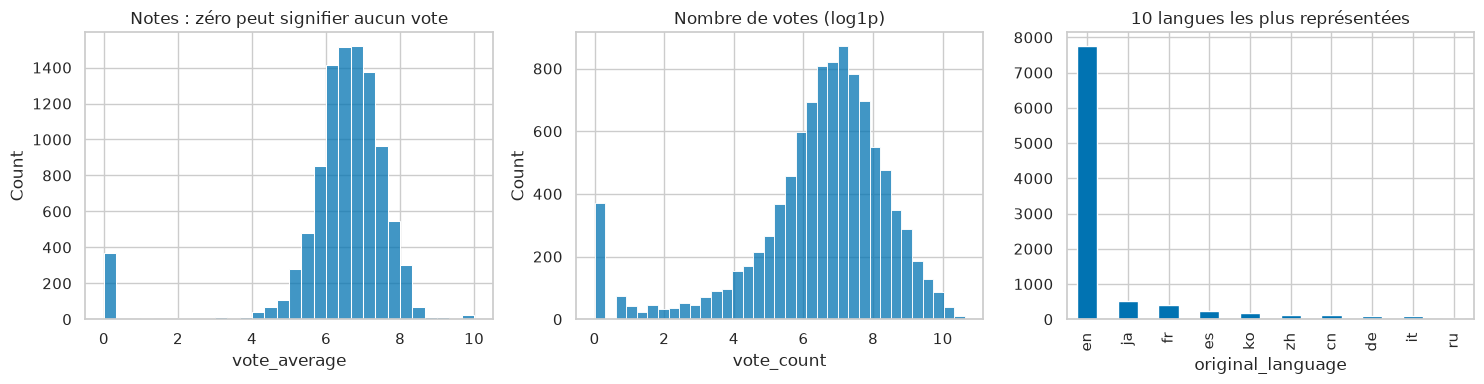

In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.histplot(raw['vote_average'],bins=30,ax=axes[0]); axes[0].set_title('Notes : zéro peut signifier aucun vote')
sns.histplot(np.log1p(raw['vote_count']),bins=35,ax=axes[1]);axes[1].set_title('Nombre de votes (log1p)')
raw['original_language'].value_counts().head(10).plot.bar(ax=axes[2]);axes[2].set_title('10 langues les plus représentées')
plt.tight_layout();plt.show()

## Prétraitement


## 3. Prétraitement et périmètre de la cible
Règles fixées **avant le split**, sans apprendre de paramètres sur le test :
- retirer l'index exporté et les doublons de film (première occurrence conservée, sans choisir selon la note) ;
- convertir les dates et les nombres, garder une cible dans [0, 10] ;
- garder les films sortis au plus tard le **22 octobre 2026** (date de publication du snapshot) et ayant **au moins 30 votes**.

Une note nulle sans vote n'est pas une mauvaise critique. Le seuil de 30 réduit cette instabilité, mais restreint
la population : les conclusions ne couvrent pas les films sans audience. Les dates invalides sont exclues car
elles empêchent de vérifier le périmètre. Les synopsis manquants deviendront des chaînes vides dans le pipeline.

In [6]:
SNAPSHOT = pd.Timestamp('2026-10-22')
df = raw.loc[:, ~raw.columns.str.startswith('Unnamed')].copy()
for col in ['vote_average','vote_count','popularity']:
    df[col] = pd.to_numeric(df[col],errors='coerce')
df['release_date'] = pd.to_datetime(df['release_date'],errors='coerce')
steps=[{'étape':'Brut','lignes':len(df)}]
df=df.drop_duplicates(subset=['id'],keep='first').copy()
steps.append({'étape':'Identifiants uniques','lignes':len(df)})
df=df.loc[df['vote_average'].between(0,10) & (df['vote_count']>=30)
          & df['release_date'].notna() & (df['release_date']<=SNAPSHOT)].copy()
steps.append({'étape':'Notes exploitables et films sortis','lignes':len(df)})
df=df.reset_index(drop=True)
display(pd.DataFrame(steps))
assert df['id'].is_unique and df['vote_average'].notna().all()
quality={'raw_rows':len(raw),'eligible_rows':len(df),'duplicate_ids':int(raw['id'].duplicated().sum())}
save_json(quality,ROOT/'reports/films_quality.json')

,étape,lignes
0,Brut,10000
1,Identifiants uniques,9856
2,Notes exploitables et films sortis,9051


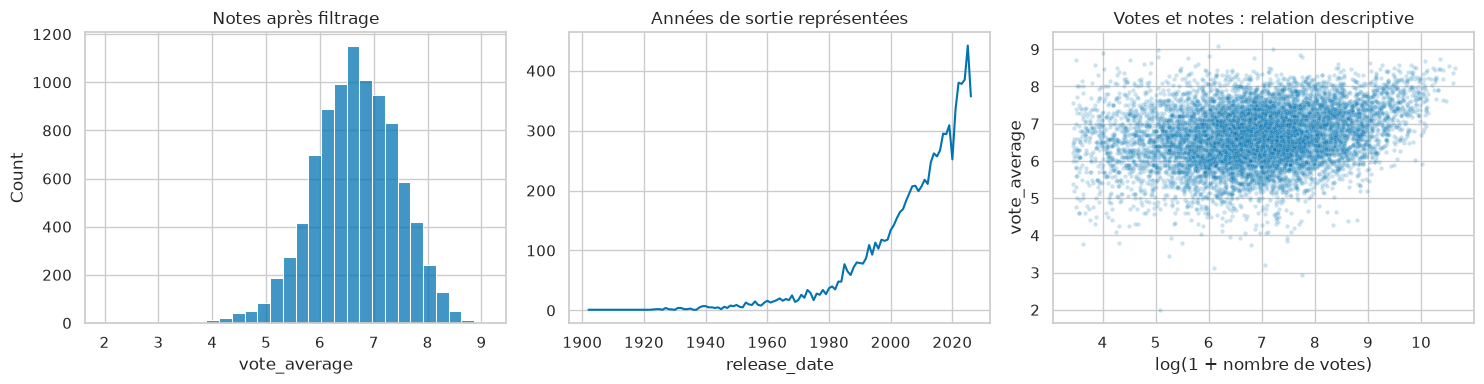

Le nettoyage conserve **9,051 films**. La note médiane est **6.68/10**. La surreprésentation de films populaires limite la généralisation à tout le cinéma.

In [7]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.histplot(df['vote_average'],bins=30,ax=axes[0]); axes[0].set_title('Notes après filtrage')
df['release_date'].dt.year.value_counts().sort_index().plot(ax=axes[1]);axes[1].set_title('Années de sortie représentées')
sns.scatterplot(x=np.log1p(df['vote_count']),y=df['vote_average'],s=10,alpha=.2,ax=axes[2]);axes[2].set_title('Votes et notes : relation descriptive');axes[2].set_xlabel('log(1 + nombre de votes)')
plt.tight_layout();plt.show()
display(Markdown(f'Le nettoyage conserve **{len(df):,} films**. La note médiane est **{df.vote_average.median():.2f}/10**. '
                'La surreprésentation de films populaires limite la généralisation à tout le cinéma.'))

## Protocole expérimental


## 4. Séparation apprentissage / validation / test
Split aléatoire reproductible **70 % / 15 % / 15 %**, après déduplication des identifiants.
Ce choix répond à une généralisation à d'autres films du même snapshot. Il ne simule pas une prévision historique :
les notes et synopsis ont été collectés à une seule date, y compris pour les films anciens.

`vote_average` est la cible. `vote_count` sert seulement au périmètre. `popularity`, les votes, le titre, l'ID et
l'index sont exclus des entrées : on n'utilise pas la réception actuelle du public pour prétendre la prévoir.
La colonne `adult`, constante dans ce fichier, n'apporte rien. Le test restera hors du choix de modèle.

In [8]:
from sklearn.model_selection import train_test_split
train_idx,hold_idx=train_test_split(df.index,test_size=.30,random_state=SEED)
valid_idx,test_idx=train_test_split(hold_idx,test_size=.50,random_state=SEED)
X_train,y_train=df.loc[train_idx,RAW_FEATURES],df.loc[train_idx,'vote_average']
X_valid,y_valid=df.loc[valid_idx,RAW_FEATURES],df.loc[valid_idx,'vote_average']
X_test,y_test=df.loc[test_idx,RAW_FEATURES],df.loc[test_idx,'vote_average']
assert not(set(df.loc[train_idx,'id']) & set(df.loc[test_idx,'id']))
assert not(set(df.loc[valid_idx,'id']) & set(df.loc[test_idx,'id']))
display(pd.DataFrame({'jeu':['train','validation','test'],'lignes':[len(train_idx),len(valid_idx),len(test_idx)]}))
# Les identifiants de split permettent de reproduire et auditer la partition.
split=pd.Series('test',index=df.index)
split.loc[train_idx]='train';split.loc[valid_idx]='validation'
df[['id']].assign(split=split).to_csv(ROOT/'reports/films_splits.csv',index=False)

,jeu,lignes
0,train,6335
1,validation,1358
2,test,1358


## Transformation


## 5. Transformation et pipelines sans fuite
La fonction commune au notebook et à l'API extrait année/mois et longueur du synopsis. Elle est déterministe.
Les paramètres appris — médianes, échelles, catégories, vocabulaire TF-IDF — sont ajustés **sur l'apprentissage seulement**.

- **Ridge + TF-IDF** : référence linéaire régularisée exploitant les mots du synopsis (texte limité à 4 000 termes).
- **Random Forest** et **Histogram Gradient Boosting** : interactions non linéaires sur les variables tabulaires.
- **Moyenne** : référence minimale indispensable pour vérifier l'utilité du ML.

On conserve un nombre réduit de configurations : Ridge avec deux régularisations, une forêt et un boosting.
L'absence de normalisation spécifique pour les arbres ne change pas leur ordre de coupure ; le même pipeline
tabulaire standardisé est conservé pour simplifier la comparaison.

In [9]:
import inspect
print(inspect.getsource(movie_features))
display(movie_features(X_train).head())

def movie_features(frame):
    frame=pd.DataFrame(frame).copy()
    dates=pd.to_datetime(frame['release_date'],errors='coerce')
    text=frame['overview'].fillna('').astype(str)
    return pd.DataFrame({'release_year':dates.dt.year.astype(float),'release_month':dates.dt.month.astype(float),
        'overview_words':np.log1p(text.str.split().str.len()),'overview_chars':np.log1p(text.str.len()),
        'original_language':frame['original_language'].fillna('unknown').astype(str),'overview':text},index=frame.index)



,release_year,release_month,overview_words,overview_chars,original_language,overview
5354,2010.0,2.0,4.553877,6.361302,en,"Detectives Jimmy and Paul, despite nine years ..."
3454,2004.0,5.0,3.496508,5.313206,en,Trainees in the FBI's psychological profiling ...
6627,2017.0,9.0,2.833213,4.532599,en,Joe reluctantly has his bachelor party even th...
5974,2013.0,2.0,3.367296,5.062595,en,A young woman with a mysterious past lands in ...
8934,2010.0,1.0,3.496508,5.093750,en,A young boy has lost his mother and is losing ...


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler,FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score

def make_pipeline(model,text=False):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    categorical=OneHotEncoder(handle_unknown='ignore',min_frequency=10,sparse_output=text)
    transforms=[('numeric',numeric,NUMERIC),('language',categorical,CATEGORICAL)]
    if text:
        transforms.append(('synopsis',TfidfVectorizer(max_features=4000,min_df=3,ngram_range=(1,2),sublinear_tf=True),'overview'))
    return Pipeline([('features',FunctionTransformer(movie_features)),
                     ('preprocess',ColumnTransformer(transforms,sparse_threshold=1.0 if text else 0.0)),
                     ('model',model)])

candidates={
    'Moyenne':make_pipeline(DummyRegressor(strategy='mean')),
    'Ridge TF-IDF alpha=10':make_pipeline(Ridge(alpha=10,solver='lsqr'),text=True),
    'Ridge TF-IDF alpha=100':make_pipeline(Ridge(alpha=100,solver='lsqr'),text=True),
    'Random Forest':make_pipeline(RandomForestRegressor(n_estimators=160,max_depth=14,min_samples_leaf=8,n_jobs=2,random_state=SEED)),
    'Histogram Gradient Boosting':make_pipeline(HistGradientBoostingRegressor(max_iter=180,max_leaf_nodes=15,l2_regularization=10,learning_rate=.06,random_state=SEED)),
}

def regression_metrics(y,p):
    return {'MAE':mean_absolute_error(y,p),'RMSE':root_mean_squared_error(y,p),'R2':r2_score(y,p)}

## ML


## 6. Apprentissage et choix sur validation
Critère principal : **MAE**, exprimée en points de note et facile à interpréter. RMSE pénalise davantage les grosses erreurs ;
R² compare à une prédiction constante (il peut être négatif). On borne les prédictions à [0, 10] pour tous les modèles,
comme le fera l'API. Aucun résultat de test n'intervient dans cette sélection.

In [11]:
validation_rows=[]
for name,pipeline in candidates.items():
    begin=time.perf_counter()
    pipeline.fit(X_train,y_train)
    pred=np.clip(pipeline.predict(X_valid),0,10)
    validation_rows.append({'modèle':name,**regression_metrics(y_valid,pred),'secondes':time.perf_counter()-begin})
validation=pd.DataFrame(validation_rows).sort_values(['MAE','RMSE']).reset_index(drop=True)
display(validation.round(4))
validation.to_csv(ROOT/'reports/films_validation.csv',index=False)
best_name=validation.iloc[0]['modèle']
print('Sélection sur validation :',best_name)

,modèle,MAE,RMSE,R2,secondes
0,Ridge TF-IDF alpha=10,0.5802,0.7360,0.1469,1.0228
1,Histogram Gradient Boosting,0.5890,0.7446,0.1268,0.4436
2,Random Forest,0.5931,0.7524,0.1084,1.2758
3,Ridge TF-IDF alpha=100,0.5943,0.7495,0.1153,0.8546
4,Moyenne,0.6377,0.7969,-0.0000,0.0674


Sélection sur validation : Ridge TF-IDF alpha=10


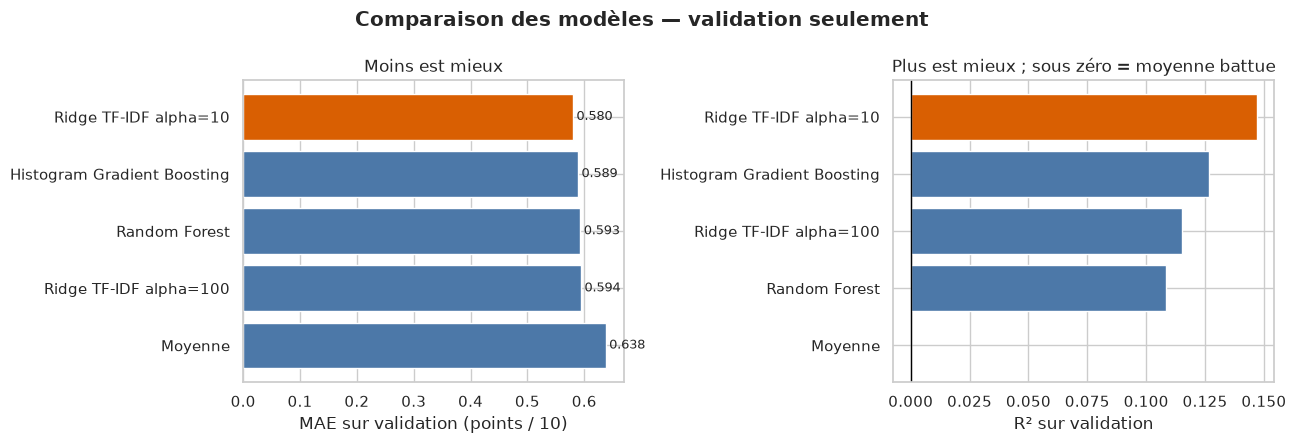

In [12]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
ordered=validation.sort_values('MAE',ascending=True)
colors=['#d95f02' if name==best_name else '#4c78a8' for name in ordered['modèle']]
axes[0].barh(ordered['modèle'],ordered['MAE'],color=colors)
axes[0].invert_yaxis();axes[0].set(xlabel='MAE sur validation (points / 10)',title='Moins est mieux')
for y,value in enumerate(ordered['MAE']): axes[0].text(value+.006,y,f'{value:.3f}',va='center',fontsize=9)
ordered_r2=validation.sort_values('R2',ascending=True)
colors=['#d95f02' if name==best_name else '#4c78a8' for name in ordered_r2['modèle']]
axes[1].barh(ordered_r2['modèle'],ordered_r2['R2'],color=colors);axes[1].axvline(0,color='black',lw=1)
axes[1].set(xlabel='R² sur validation',title='Plus est mieux ; sous zéro = moyenne battue')
plt.suptitle('Comparaison des modèles — validation seulement',fontweight='bold')
plt.tight_layout();plt.show()

### Lire la comparaison
Les deux graphiques utilisent **uniquement la validation** : ils justifient le choix avant d'ouvrir le test.
La couleur orange marque le modèle retenu. La référence de prédiction moyenne donne une base lisible ; R² négatif
signifie que la moyenne aurait fait mieux sur cette validation.

## Éval


## 7. Réentraînement et évaluation finale
Le modèle choisi est réentraîné sur **train + validation**, sans changer ses hyperparamètres.
Le test est ensuite ouvert une seule fois. Une référence moyenne réentraînée sur le même ensemble est aussi mesurée.
Un bootstrap du test fournit un intervalle indicatif de MAE ; il ne couvre pas l'incertitude du choix de modèle
ni le biais de sélection du catalogue.

In [13]:
X_fit=pd.concat([X_train,X_valid]);y_fit=pd.concat([y_train,y_valid])
final_model=clone(candidates[best_name]).fit(X_fit,y_fit)
test_pred=np.clip(final_model.predict(X_test),0,10)
baseline_pred=np.full(len(y_test),y_fit.mean())
test_metrics=regression_metrics(y_test,test_pred)
display(pd.DataFrame([{'modèle':best_name,**test_metrics},
                     {'modèle':'Moyenne train+validation',**regression_metrics(y_test,baseline_pred)}]).round(4))
rng=np.random.default_rng(SEED)
errors=np.abs(y_test.to_numpy()-test_pred)
boot=np.array([rng.choice(errors,size=len(errors),replace=True).mean() for _ in range(500)])
ci=np.quantile(boot,[.025,.975])
print(f'IC bootstrap 95 % de la MAE : [{ci[0]:.3f}, {ci[1]:.3f}]')
save_json({'selected_model':best_name,'test':test_metrics,'mae_bootstrap_ci95':ci.tolist(),
           'baseline_test':regression_metrics(y_test,baseline_pred),'n_test':len(y_test)},ROOT/'reports/films_test.json')

,modèle,MAE,RMSE,R2
0,Ridge TF-IDF alpha=10,0.5673,0.7191,0.1470
1,Moyenne train+validation,0.6223,0.7790,-0.0008


IC bootstrap 95 % de la MAE : [0.546, 0.590]


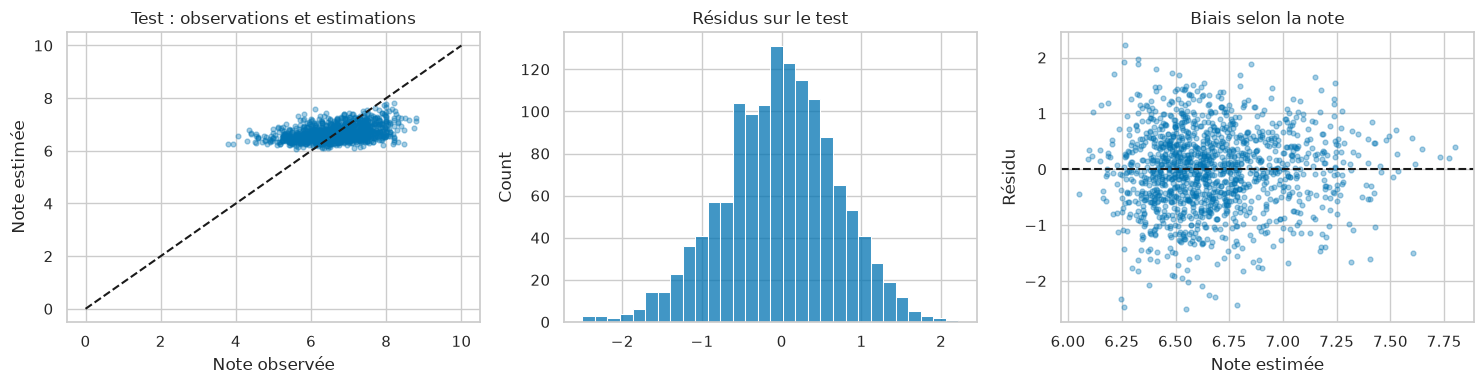

,n,MAE
language,,
es,25,0.695443
fr,59,0.653941
ko,36,0.594312
en,1073,0.573746
ja,60,0.489747
cn,20,0.329405


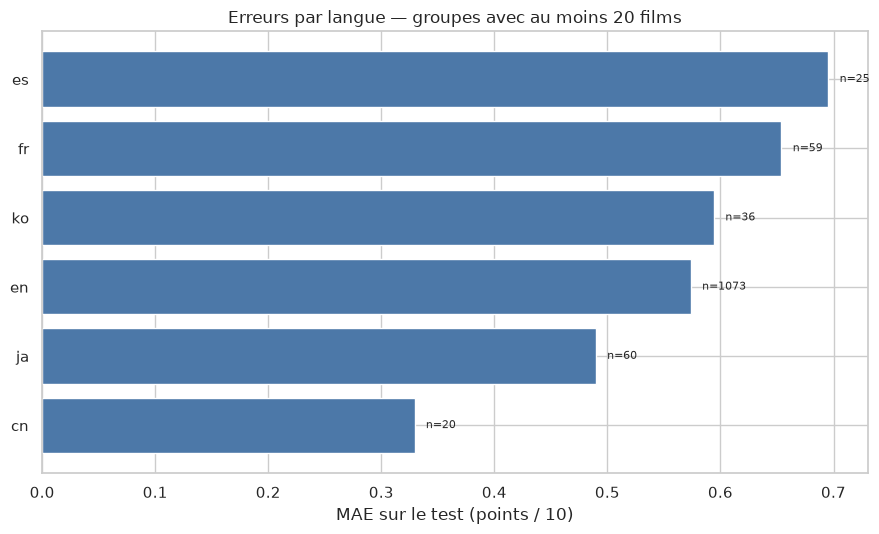

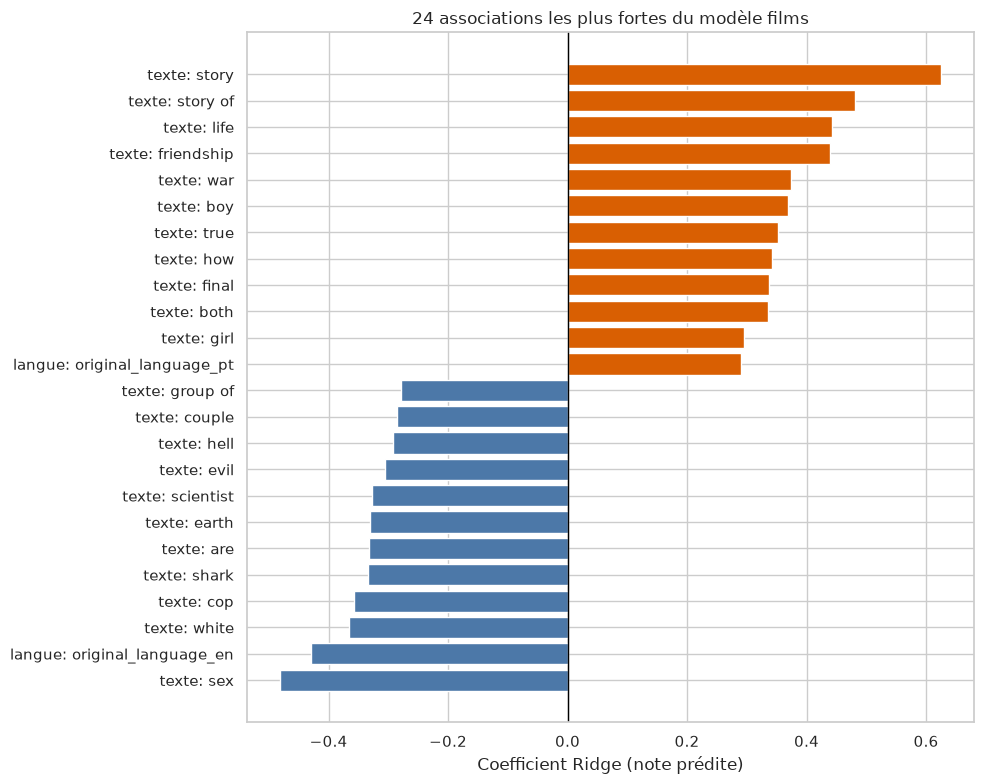

,variable,coefficient
3063,synopsis__story,0.624915
2893,synopsis__sex,-0.480919
3064,synopsis__story of,0.480909
1979,synopsis__life,0.442881
1292,synopsis__friendship,0.438861
7,language__original_language_en,-0.428649
3816,synopsis__war,0.373750
487,synopsis__boy,0.368771
3886,synopsis__white,-0.365779
744,synopsis__cop,-0.357205


In [14]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].scatter(y_test,test_pred,s=12,alpha=.35);axes[0].plot([0,10],[0,10],'k--');axes[0].set(xlabel='Note observée',ylabel='Note estimée',title='Test : observations et estimations')
sns.histplot(y_test.to_numpy()-test_pred,bins=30,ax=axes[1]);axes[1].set_title('Résidus sur le test')
axes[2].scatter(test_pred,y_test.to_numpy()-test_pred,s=12,alpha=.35);axes[2].axhline(0,color='k',linestyle='--');axes[2].set(xlabel='Note estimée',ylabel='Résidu',title='Biais selon la note')
plt.tight_layout();plt.show()
# Diagnostic par langue, sans modifier le modèle après lecture du test.
diagnostics=pd.DataFrame({'language':X_test.original_language,'abs_error':errors})
language_errors=(diagnostics.groupby('language').agg(n=('abs_error','size'),MAE=('abs_error','mean'))
                .query('n >= 20').sort_values('MAE',ascending=False))
display(language_errors)
show_languages=language_errors.head(12).sort_values('MAE')
fig,ax=plt.subplots(figsize=(9,5.5))
ax.barh(show_languages.index.astype(str),show_languages['MAE'],color='#4c78a8')
ax.set(xlabel='MAE sur le test (points / 10)',title='Erreurs par langue — groupes avec au moins 20 films')
for y,(value,n) in enumerate(zip(show_languages['MAE'],show_languages['n'])):
    ax.text(value+.01,y,f'n={int(n)}',va='center',fontsize=8)
plt.tight_layout();plt.show()
# Ridge permet une visualisation compacte des associations apprises, y compris des mots du synopsis.
if hasattr(final_model.named_steps['model'],'coef_'):
    feature_names=final_model.named_steps['preprocess'].get_feature_names_out()
    coefficients=np.asarray(final_model.named_steps['model'].coef_).ravel()
    coef_table=pd.DataFrame({'variable':feature_names,'coefficient':coefficients})
    top_coef=pd.concat([coef_table.nsmallest(12,'coefficient'),coef_table.nlargest(12,'coefficient')]).drop_duplicates('variable')
    top_coef=top_coef.sort_values('coefficient')
    fig,ax=plt.subplots(figsize=(10,8))
    colors=np.where(top_coef['coefficient']>0,'#d95f02','#4c78a8')
    ax.barh(top_coef['variable'].str.replace('synopsis__','texte: ',regex=False).str.replace('numeric__','num: ',regex=False).str.replace('language__','langue: ',regex=False),top_coef['coefficient'],color=colors)
    ax.axvline(0,color='black',lw=1)
    ax.set(xlabel='Coefficient Ridge (note prédite)',title='24 associations les plus fortes du modèle films')
    plt.tight_layout();plt.show()
    display(top_coef.sort_values('coefficient',key=lambda v:v.abs(),ascending=False).head(16))

### Interprétation et limites
L'erreur est à comparer à celle du prédicteur moyen. Les caractéristiques disponibles expliquent seulement une partie
de l'appréciation du public : casting, budget, distribution et genres ne sont pas présents.
Une estimation centrale peut masquer de fortes erreurs sur les notes extrêmes.
Le synopsis peut avoir été révisé après sortie ; nous ne revendiquons donc pas une évaluation pré-sortie.
Les diagnostics de test servent à décrire les limites, pas à choisir un nouveau modèle.

In [15]:
base_mae=mean_absolute_error(y_test,baseline_pred)
gain=100*(base_mae-test_metrics['MAE'])/base_mae
display(Markdown(f'**Résultat mesuré :** {best_name}, MAE **{test_metrics["MAE"]:.3f}/10**, '
                f'RMSE **{test_metrics["RMSE"]:.3f}**, R² **{test_metrics["R2"]:.3f}**. '
                f'Écart relatif de MAE face à la moyenne : **{gain:+.1f} %** de réduction.'))

**Résultat mesuré :** Ridge TF-IDF alpha=10, MAE **0.567/10**, RMSE **0.719**, R² **0.147**. Écart relatif de MAE face à la moyenne : **+8.8 %** de réduction.

## Déploiement


## 8. Déploiement : pipeline complet et API FastAPI locale
Le pipeline sérialisé contient les transformations et le modèle, évitant un encodage différent à l'inférence.
L'API reçoit les trois entrées brutes et renvoie une note estimée. Les schémas d'entrée refusent les champs
inconnus et les lots vides. Les scores ne constituent pas une recommandation personnalisée.

In [16]:
import joblib
out=ROOT/'artifacts/films';out.mkdir(parents=True,exist_ok=True)
joblib.dump(final_model,out/'pipeline.joblib')
metadata={'model':best_name,'target':'vote_average','features':RAW_FEATURES,'snapshot':'2026-10-22',
          'minimum_votes':30,'seed':SEED,'validation_mae':float(validation.iloc[0]['MAE']),
          'test_metrics':test_metrics,'clip':[0,10]}
save_json(metadata,out/'metadata.json')
example=X_test.iloc[0].copy()
example['release_date']=pd.Timestamp(example['release_date']).strftime('%Y-%m-%d')
example['overview']='' if pd.isna(example['overview']) else str(example['overview'])
payload={'movies':[example.to_dict()]}
save_json(payload,ROOT/'example_film_request.json')
loaded=joblib.load(out/'pipeline.joblib')
np.testing.assert_allclose(loaded.predict(X_test.iloc[:10]),final_model.predict(X_test.iloc[:10]))
print('Pipeline sauvegardé, rechargé et prédictions identiques.')

Pipeline sauvegardé, rechargé et prédictions identiques.


In [17]:
from contextlib import asynccontextmanager
from datetime import date
from fastapi import FastAPI
from pydantic import BaseModel, ConfigDict, Field
from fastapi.testclient import TestClient

class Movie(BaseModel):
    model_config=ConfigDict(extra='forbid')
    release_date: date
    original_language: str=Field(min_length=2,max_length=10)
    overview: str=Field(default='',max_length=20000)
class MovieBatch(BaseModel):
    model_config=ConfigDict(extra='forbid')
    movies: list[Movie]=Field(min_length=1,max_length=100)

@asynccontextmanager
async def lifespan(app):
    app.state.model=joblib.load(ROOT/'artifacts/films/pipeline.joblib')
    app.state.metadata=json.loads((ROOT/'artifacts/films/metadata.json').read_text())
    yield
app=FastAPI(title='TP3 — Estimation des notes de films',version='1.0.0',lifespan=lifespan,
    description='Estimation de note moyenne à partir de la date, langue et synopsis.')
@app.get('/health')
def health():
    return {'status':'ok','model':app.state.metadata['model'],'task':'regression'}
@app.post('/predict')
def predict(request:MovieBatch):
    records=[movie.model_dump(mode='json') for movie in request.movies]
    ratings=np.clip(app.state.model.predict(pd.DataFrame(records)),0,10)
    return {'model':app.state.metadata['model'],
            'predictions':[{'estimated_rating':round(float(value),4)} for value in ratings]}

with TestClient(app) as client:
    response=client.post('/predict',json=payload)
    assert response.status_code==200,response.text
    expected=float(np.clip(final_model.predict(pd.DataFrame(payload['movies']))[0],0,10))
    assert abs(response.json()['predictions'][0]['estimated_rating']-expected)<1e-3
    assert client.post('/predict',json={'movies':[]}).status_code==422
    assert client.post('/predict',json={'movies':[dict(payload['movies'][0],unknown=1)]}).status_code==422
    print('Health :',client.get('/health').json())
    print('Prédiction API :',response.json())
print('Contrat, rechargement et cohérence notebook/API vérifiés.')

/home/omar/Bureau/5A/big data/TP 3/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


Health : {'status': 'ok', 'model': 'Ridge TF-IDF alpha=10', 'task': 'regression'}
Prédiction API : {'model': 'Ridge TF-IDF alpha=10', 'predictions': [{'estimated_rating': 6.9422}]}
Contrat, rechargement et cohérence notebook/API vérifiés.


### Lancer le service

Après avoir exécuté la cellule de test ci-dessus, lance le serveur depuis une nouvelle cellule du notebook :

```python
import uvicorn
uvicorn.run(app, host="127.0.0.1", port=8001)
```

Documentation interactive : **http://127.0.0.1:8001/docs**. Arrêt avec `Ctrl+C`.

## 9. Bilan et références
Nous avons construit une chaîne reproductible et mesuré ses limites. Une amélioration future demanderait des
variables plus riches et un nouveau protocole de validation, pas des ajustements sur le test déjà consulté.

- [Dataset original et licence CC0](https://www.kaggle.com/datasets/sahilk22/trending-movies-analysis-up-to-2026)
- [kagglehub : téléchargement versionné](https://github.com/Kaggle/kagglehub)
- [Scikit-learn : pipelines et prévention des fuites](https://scikit-learn.org/1.7/common_pitfalls.html)
- [FastAPI : tests d'application](https://fastapi.tiangolo.com/tutorial/testing/)

Le code nécessaire à cette partie est inclus dans le notebook.